# Maths project V1 : construction du dataset marché japonais

Objectif : construire **pas à pas** un dataset quotidien (une ligne par jour de bourse de Tokyo) qui réunit :

1. Les indices actions (Nikkei 225, S&P 500, TAIEX, Shanghai, Nifty, MSCI EM, TOPIX et ses sous-indices)
2. Les taux longs (US 10 ans, JGB, Bund) et les taux courts (€STR/EONIA, Euribor, TONA)
3. Le change (USD/JPY, EUR/JPY) et la volatilité (VIX)
4. La macro japonaise (CPI, Tankan)
5. Le calendrier des réunions de la Banque du Japon
6. **Les news** (GDELT : ton et volume des articles sur le Japon et la BoJ)
7. Les indicateurs techniques calculés à partir du Nikkei

**Règle d'or : pas de fuite d'information.** Une ligne datée t ne doit contenir que ce qui était *publié* à la date t.

**Fichiers produits** (dossier `data/`) :

| Fichier | Contenu | Cases vides |
|---|---|---|
| `dataset_ml.csv` | 2010 → aujourd'hui, toutes les variables sauf les news | **aucune** |
| `dataset_ml_news.csv` | 2017 → aujourd'hui, toutes les variables **avec les news** | **aucune** |
| `dataset_daily.csv` | tout, avant décalage horaire, pour l'exploration | seulement là où une série n'existait pas encore |

**Exécution rapide** : chaque source est sauvegardée dans `data/raw/`. Tant que ce fichier a moins de
`CACHE_HOURS` heures, il est relu depuis le disque (instantané, sans réseau). Si un site ne répond pas,
on reprend sa dernière version sauvegardée : le notebook ne reste jamais bloqué.

## Étape 0 : installation, imports et paramètres

In [32]:
# N'installe que ce qui manque (évite un pip à chaque exécution)
import importlib.util
missing = [p for p in ["yfinance", "requests", "pandas", "numpy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    %pip install -q {" ".join(missing)}
    print("Installé :", missing, "-> redémarre le kernel puis relance tout")
else:
    print("Toutes les librairies sont déjà installées")

Toutes les librairies sont déjà installées


Pourquoi deux dates de début ?

- `START` : début du dataset final.
- `FETCH_START` : on télécharge **un an plus tôt**. Sans cet historique, les 200 premiers jours n'auraient pas de
  moyenne mobile 200 jours, les 12 premiers mois pas d'inflation sur un an, le premier trimestre pas de Tankan… :
  ce sont ces trous qui faisaient les cases vides au début du dataset.
- `NEWS_START` : GDELT ne fournit pas de séries quotidiennes avant 2017.

⚠️ Si tu modifies une de ces dates, mets `CACHE_HOURS = 0` pour une exécution, afin de retélécharger les sources.

In [33]:
import io
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt

START = "2010-01-01"        # début du dataset final
FETCH_START = "2009-01-01"  # début des téléchargements (1 an d'amorçage pour les calculs)
NEWS_START = "2017-01-01"   # GDELT ne remonte pas avant 2017
CACHE_HOURS = 24            # 0 = toujours retélécharger ; 1e9 = ne jamais retélécharger

DATA = Path("../data/2_construites")   # jeux construits
RAW = Path("../data/1_brutes")            # une copie de chaque source (sert aussi de cache)
MANUAL = RAW / "saisie_manuelle"      # CSV à déposer à la main (Nikkei VI, PMI, ...)
for d in (RAW, MANUAL):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

### Deux fonctions utilitaires

**`get(url)`** : un `GET` HTTP qui **échoue vite** (5 s pour se connecter, 15 s pour lire, 3 essais au maximum)
au lieu de bloquer le notebook pendant des minutes.

⚠️ On n'envoie **pas** de User-Agent de navigateur (« Mozilla/… ») : FRED laisse ces requêtes sans réponse puis coupe
la connexion (`RemoteDisconnected` / `Connection aborted`). L'en-tête par défaut de `requests` passe partout.

**`load_source(nom, fonction_de_téléchargement)`** :
1. si `data/raw/<nom>.csv` existe et a moins de `CACHE_HOURS` heures, on le relit, sans réseau ;
2. sinon on télécharge et on sauvegarde ;
3. si le téléchargement échoue (ou renvoie un tableau vide), on reprend le fichier sauvegardé, même ancien ;
   s'il n'existe pas, la source est ignorée (`None`) et le reste du notebook continue.

In [34]:
session = requests.Session()

def get(url, timeout=(5, 15), retries=3, **kwargs):
    for i in range(retries):
        try:
            r = session.get(url, timeout=timeout, **kwargs)
            r.raise_for_status()
            return r
        except requests.RequestException as e:
            if i == retries - 1:
                raise
            print(f"  essai {i + 1} échoué ({type(e).__name__}), nouvel essai...")
            time.sleep(2)


def load_source(name, download):
    path = RAW / f"{name}.csv"
    read_cache = lambda: pd.read_csv(path, index_col=0, parse_dates=True)
    age_h = (time.time() - path.stat().st_mtime) / 3600 if path.exists() else None

    if age_h is not None and age_h < CACHE_HOURS:
        df = read_cache()
        print(f"[cache] {name} : relu depuis {path} (sauvegardé il y a {age_h:.1f} h)")
    else:
        t0 = time.time()
        try:
            df = download()
            if df is None or df.dropna(how="all").empty:
                raise ValueError("réponse vide")              # yfinance renvoie un tableau vide au lieu d'une erreur
            if age_h is not None:
                df = df.combine_first(read_cache())            # complète un téléchargement partiel (ticker manquant)
            df.to_csv(path)
            print(f"[web]   {name} : téléchargé en {time.time() - t0:.1f} s")
        except Exception as e:
            print(f"[ÉCHEC] {name} : {type(e).__name__}: {str(e)[:120]}")
            if age_h is None:
                print(f"        pas de sauvegarde disponible -> source ignorée")
                return None
            df = read_cache()
            print(f"        -> dernière sauvegarde utilisée (vieille de {age_h:.0f} h)")
    print(f"        {len(df)} lignes, {df.index.min().date()} -> {df.index.max().date()}")
    return df

## Étape 1 : Nikkei 225 (Yahoo Finance)

Le Nikkei 225 est la **série de référence** : son calendrier (jours de bourse de Tokyo) sera l'index du dataset final.
On garde l'OHLCV complet (ouverture, plus haut, plus bas, clôture, volume) pour calculer les indicateurs techniques.

In [35]:
def download_nikkei():
    d = yf.download("^N225", start=FETCH_START, auto_adjust=False, progress=False, multi_level_index=False, timeout=30)
    if d.empty:
        raise RuntimeError("Yahoo n'a rien renvoyé")
    d = d[["Open", "High", "Low", "Close", "Volume"]]
    d.columns = ["n225_open", "n225_high", "n225_low", "n225_close", "n225_volume"]
    return d.dropna(subset=["n225_close"])

n225 = load_source("nikkei225", download_nikkei)
assert n225 is not None, "Le Nikkei est indispensable (calendrier de référence) : vérifie ta connexion internet."
n225.tail(3)

[cache] nikkei225 : relu depuis data/raw/nikkei225.csv (sauvegardé il y a 2.8 h)
        4361 lignes, 2009-01-05 -> 2026-11-09


,n225_open,n225_high,n225_low,n225_close,n225_volume
Date,,,,,
2026-11-05,62384.730469,62653.980469,60786.191406,61077.898438,290000000
2026-11-06,60374.351562,60374.351562,56745.808594,57434.769531,314400000
2026-11-09,57960.699219,59440.179688,57775.160156,58775.500000,0


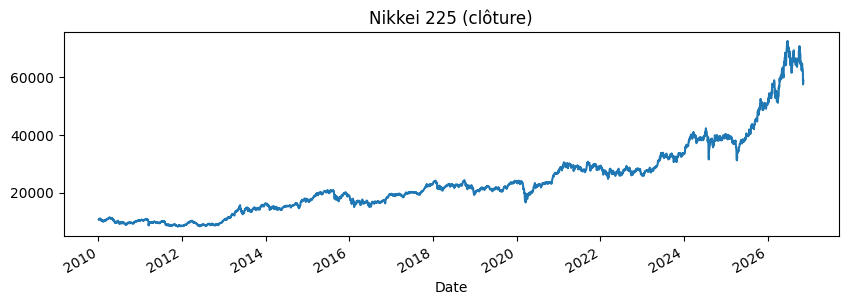

In [36]:
n225.loc[START:, "n225_close"].plot(figsize=(10, 3), title="Nikkei 225 (clôture)");

## Étape 2 : autres indices, ETF et change (Yahoo Finance)

| Ticker | Colonne | Remarque |
|---|---|---|
| ^GSPC, ^TWII, 000001.SS, ^NSEI | sp500, taiex, shanghai, nifty50 | |
| EEM | msci_em_eem | ETF iShares, **proxy** du MSCI EM (en USD) |
| 1306.T | topix_etf | ETF NEXT FUNDS TOPIX, proxy du TOPIX |
| 1311.T | topix_core30_etf | proxy du TOPIX Core30 |
| 2516.T | growth250_etf | proxy du TSE Growth 250, **coté seulement depuis 2018** (exclu des fichiers ML) |
| JPY=X, EURJPY=X | usdjpy_yahoo, eurjpy | |
| ^TNX, ^VIX | us10y_yahoo, vix_yahoo | secours si FRED (étape 3) ne répond pas |

Le TOPIX et ses sous-indices sont absents ou incomplets sur Yahoo : les ETF servent de substituts.
Les indices officiels (JPX, Investing.com) peuvent être ajoutés à l'étape 11.

In [37]:
YAHOO = {
    "^GSPC": "sp500",
    "^TWII": "taiex",
    "000001.SS": "shanghai",
    "^NSEI": "nifty50",
    "EEM": "msci_em_eem",
    "1306.T": "topix_etf",
    "1311.T": "topix_core30_etf",
    "2516.T": "growth250_etf",
    "JPY=X": "usdjpy_yahoo",
    "EURJPY=X": "eurjpy",
    "^TNX": "us10y_yahoo",
    "^VIX": "vix_yahoo",
}

def download_yahoo():
    d = yf.download(list(YAHOO), start=FETCH_START, auto_adjust=False, progress=False, timeout=30)["Close"]
    return d.rename(columns=YAHOO)[list(YAHOO.values())]

yahoo = load_source("yahoo_others", download_yahoo)
yahoo.tail(3) if yahoo is not None else None

[cache] yahoo_others : relu depuis data/raw/yahoo_others.csv (sauvegardé il y a 2.8 h)
        4659 lignes, 2009-01-01 -> 2026-11-09


,sp500,taiex,shanghai,nifty50,msci_em_eem,topix_etf,topix_core30_etf,growth250_etf,usdjpy_yahoo,eurjpy,us10y_yahoo,vix_yahoo
Date,,,,,,,,,,,,
2026-11-05,7353.729980,41574.718750,3689.910889,24536.599609,58.049999,415.600006,2074.0,597.599976,158.356995,177.908997,4.837,28.180000
2026-11-06,7376.859863,39701.640625,3649.177002,25030.349609,59.330002,388.600006,1960.0,574.299988,157.498001,176.820999,4.859,25.639999
2026-11-09,NaN,41661.699219,3660.791748,25044.650391,NaN,402.100006,2015.0,576.400024,NaN,176.776993,NaN,23.559999


In [38]:
# Première date disponible par série : 2516.T ne commence qu'en 2018
yahoo.apply(lambda s: s.first_valid_index()).dt.date if yahoo is not None else None

sp500               2009-01-02
taiex               2009-01-05
shanghai            2009-01-05
nifty50             2009-01-02
msci_em_eem         2009-01-02
topix_etf           2009-01-05
topix_core30_etf    2009-01-05
growth250_etf       2018-01-30
usdjpy_yahoo        2009-01-01
eurjpy              2009-01-01
us10y_yahoo         2009-01-02
vix_yahoo           2009-01-02
dtype: object

## Étape 3 : FRED (US 10 ans, USD/JPY, VIX)

FRED propose un téléchargement CSV direct, sans clé d'API :
`https://fred.stlouisfed.org/graph/fredgraph.csv?id=<SERIE>&cosd=<début>`. Les valeurs manquantes y sont notées `.`.

- `DGS10` : rendement du Treasury 10 ans
- `DEXJPUS` : USD/JPY (taux de midi à New York)
- `VIXCLS` : VIX (clôture)

**Si FRED ne répond pas**, on utilise les séries Yahoo de l'étape 2 : `^TNX` (même valeur que DGS10 à ±0,01 point)
et `^VIX`. Le dataset est donc complet dans tous les cas.

In [39]:
def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}&cosd={FETCH_START}"
    s = pd.read_csv(io.StringIO(get(url).text), index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    return pd.to_numeric(s, errors="coerce").dropna()

def download_fred():
    return pd.DataFrame({"us10y": fred("DGS10"), "usdjpy_fred": fred("DEXJPUS"), "vix": fred("VIXCLS")})

fred_df = load_source("fred", download_fred)
if fred_df is None:
    print("-> secours Yahoo : us10y = ^TNX, vix = ^VIX")
    if yahoo is not None and {"us10y_yahoo", "vix_yahoo"} <= set(yahoo.columns):
        yb = yahoo
    else:
        yb = (yf.download(["^TNX", "^VIX"], start=FETCH_START, auto_adjust=False, progress=False, timeout=30)["Close"]
              .rename(columns={"^TNX": "us10y_yahoo", "^VIX": "vix_yahoo"}))
    fred_df = pd.DataFrame({"us10y": yb.get("us10y_yahoo"), "vix": yb.get("vix_yahoo")}).dropna(how="all")
fred_df.tail(3)

[cache] fred : relu depuis data/raw/fred.csv (sauvegardé il y a 2.8 h)
        4543 lignes, 2009-01-02 -> 2026-11-05


,us10y,usdjpy_fred,vix
observation_date,,,
2026-11-03,4.95,NaN,20.83
2026-11-04,4.90,NaN,16.61
2026-11-05,4.84,NaN,28.18


## Étape 4 : JGB, la courbe des taux japonais (ministère des Finances)

Le MOF publie deux fichiers :
- `jgbcme_all.csv` : tout l'historique depuis 1974, **jusqu'au mois précédent**
- `jgbcme.csv` : le mois en cours

Format : une ligne de titre à sauter, des dates `AAAA/M/J`, et `-` pour les valeurs absentes.
On concatène les deux fichiers et on garde les maturités 2, 5, 10 et 30 ans.

In [40]:
def download_jgb():
    frames = []
    for url in ["https://www.mof.go.jp/english/policy/jgbs/reference/interest_rate/historical/jgbcme_all.csv",
                "https://www.mof.go.jp/english/policy/jgbs/reference/interest_rate/jgbcme.csv"]:
        df = pd.read_csv(io.StringIO(get(url).text), skiprows=1, na_values="-")
        df["Date"] = pd.to_datetime(df["Date"], format="%Y/%m/%d", errors="coerce")
        frames.append(df.dropna(subset=["Date"]).set_index("Date"))
    jgb = pd.concat(frames)
    jgb = jgb[~jgb.index.duplicated(keep="last")]
    jgb = jgb[["2Y", "5Y", "10Y", "30Y"]].apply(pd.to_numeric, errors="coerce")
    jgb.columns = ["jgb2y", "jgb5y", "jgb10y", "jgb30y"]
    return jgb.loc[FETCH_START:]

jgb = load_source("mof_jgb", download_jgb)
jgb.tail(3) if jgb is not None else None

[cache] mof_jgb : relu depuis data/raw/mof_jgb.csv (sauvegardé il y a 2.8 h)
        4363 lignes, 2009-01-05 -> 2026-11-06


,jgb2y,jgb5y,jgb10y,jgb30y
Date,,,,
2026-11-04,1.891,2.269,2.855,3.979
2026-11-05,1.860,2.210,2.806,3.915
2026-11-06,1.732,2.070,2.696,3.898


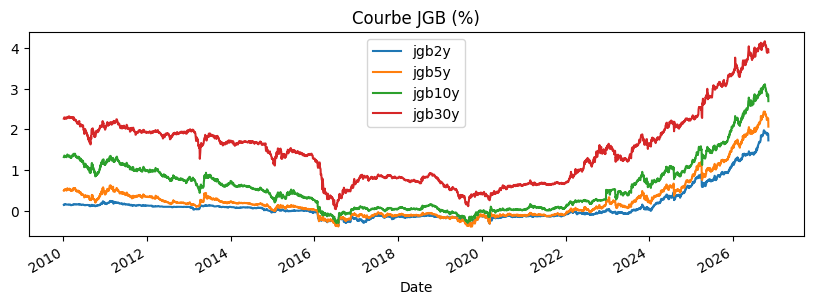

In [41]:
if jgb is not None:
    jgb.loc[START:].plot(figsize=(10, 3), title="Courbe JGB (%)");

## Étape 5 : Bund 10 ans (Bundesbank)

Série quotidienne `BBSIS.D.I.ZST.ZI.EUR.S1311.B.A604.R10XX.R.A.A._Z._Z.A` : rendement à 10 ans des titres fédéraux
allemands, estimé par la méthode de Svensson. Le CSV contient 9 lignes de métadonnées avant les données, et `.` pour
les jours sans valeur (week-ends).

In [42]:
def download_bund():
    key = "D.I.ZST.ZI.EUR.S1311.B.A604.R10XX.R.A.A._Z._Z.A"
    r = get(f"https://api.statistiken.bundesbank.de/rest/download/BBSIS/{key}?format=csv&lang=en")
    df = pd.read_csv(io.StringIO(r.text.lstrip("\ufeff")), skiprows=9, header=None, usecols=[0, 1],
                     names=["date", "bund10y"], na_values=".")
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df.dropna().set_index("date").loc[FETCH_START:]

bund = load_source("bundesbank_bund10y", download_bund)

[cache] bundesbank_bund10y : relu depuis data/raw/bundesbank_bund10y.csv (sauvegardé il y a 2.8 h)
        4535 lignes, 2009-01-02 -> 2026-11-09


## Étape 6 : taux courts EUR (BCE)

API du ECB Data Portal (`https://data-api.ecb.europa.eu/service/data/<flux>/<clé>?format=csvdata&startPeriod=...`) :

- **€STR** (`EST/B.EU000A2X2A25.WT`) : taux au jour le jour, seulement depuis octobre 2019
- **EONIA** (`EON/D.EONIA_TO.RATE`) : son prédécesseur, arrêté fin 2021
- **Euribor 3 mois** (`FM/M.U2.EUR.RT.MM.EURIBOR3MD_.HSTA`) : **moyenne mensuelle**, l'Euribor quotidien n'étant pas en accès libre

On ne garde qu'une colonne de taux au jour le jour, `eur_overnight` = EONIA avant l'€STR, puis €STR : une série
continue depuis 2009, sans case vide. L'Euribor mensuel n'est connu qu'en fin de mois : on le date au dernier jour du mois.

In [43]:
def ecb(flow_key):
    r = get(f"https://data-api.ecb.europa.eu/service/data/{flow_key}?format=csvdata&startPeriod={FETCH_START}")
    df = pd.read_csv(io.StringIO(r.text), usecols=["TIME_PERIOD", "OBS_VALUE"])
    df["TIME_PERIOD"] = pd.to_datetime(df["TIME_PERIOD"])
    return df.set_index("TIME_PERIOD")["OBS_VALUE"]

def download_ecb():
    estr = ecb("EST/B.EU000A2X2A25.WT")
    eonia = ecb("EON/D.EONIA_TO.RATE")
    euribor3m = ecb("FM/M.U2.EUR.RT.MM.EURIBOR3MD_.HSTA")
    euribor3m.index = euribor3m.index + pd.offsets.MonthEnd(0)   # disponible en fin de mois
    # Les trois séries sont mises dans le même tableau AVANT de les combiner,
    # sinon l'EONIA ne serait gardé qu'aux dates de l'Euribor (une par mois).
    df = pd.DataFrame({"estr": estr, "eonia": eonia, "euribor3m_mavg": euribor3m})
    df["eur_overnight"] = df["estr"].combine_first(df["eonia"])
    return df[["eur_overnight", "euribor3m_mavg"]]

ecb_df = load_source("ecb", download_ecb)

[cache] ecb : relu depuis data/raw/ecb.csv (sauvegardé il y a 2.8 h)
        4634 lignes, 2009-01-02 -> 2026-11-06


## Étape 7 : TONA et Tankan (API de la Banque du Japon)

La BoJ propose une API JSON gratuite (`stat-search.boj.or.jp/api/v1/getDataCode`). On donne une base (`db`) et un
code de série, et on reçoit deux listes : `SURVEY_DATES` et `VALUES`.

- **TONA** : `db=FM01`, `code=STRDCLUCON` (call rate au jour le jour non garanti), quotidien
- **Tankan** : `db=CO`, DI « conditions des affaires » des grandes entreprises, trimestriel :
  - `TK99F1000601GCQ01000` : industrie, constaté
  - `TK99F2000601GCQ01000` : hors industrie, constaté
  - `TK99F1000601GCQ11000` : industrie, prévision à 3 mois

In [44]:
def boj(db, code, start=FETCH_START):
    url = (f"https://www.stat-search.boj.or.jp/api/v1/getDataCode?format=json&lang=en"
           f"&db={db}&code={code}&startDate={start[:4]}01")
    j = get(url).json()
    if j.get("STATUS") != 200 or not j.get("RESULTSET"):
        raise RuntimeError(f"BoJ {code}: {j.get('MESSAGE')}")
    v = j["RESULTSET"][0]["VALUES"]
    return pd.Series(v["VALUES"], index=[str(x) for x in v["SURVEY_DATES"]], dtype="float64").dropna()

def download_tona():
    s = boj("FM01", "STRDCLUCON")
    s.index = pd.to_datetime(s.index, format="%Y%m%d")
    return s.rename("tona").to_frame()

tona = load_source("boj_tona", download_tona)

[cache] boj_tona : relu depuis data/raw/boj_tona.csv (sauvegardé il y a 2.8 h)
        4362 lignes, 2009-01-05 -> 2026-11-05


**Dates du Tankan.** La BoJ code le trimestre en `AAAAQQ` (ex. `202603` = T3 2026). Deux pièges :

1. **Publication** : l'enquête du trimestre T est publiée vers le 1er jour ouvré qui suit la fin de T (mi-décembre
   pour l'enquête de décembre). On la rend disponible **5 jours après la fin du trimestre**, par prudence.
2. **La prévision est datée par le trimestre visé**, pas par celui où elle a été publiée : la prévision pour T4
   publiée en octobre porte la date T4. On la ramène d'un trimestre, sinon elle arriverait trois mois trop tard dans le dataset.

In [45]:
TANKAN = {"tankan_large_manuf": "TK99F1000601GCQ01000",
          "tankan_large_nonmanuf": "TK99F2000601GCQ01000",
          "tankan_large_manuf_fcst": "TK99F1000601GCQ11000"}

def download_tankan():
    out = {}
    for name, code_ in TANKAN.items():
        s = boj("CO", code_)
        q = pd.PeriodIndex([f"{x[:4]}Q{int(x[4:])}" for x in s.index], freq="Q")
        if name.endswith("_fcst"):
            q = q - 1                                   # trimestre d'enquête et non trimestre visé
        out[name] = pd.Series(s.values, index=q.to_timestamp(how="end").normalize())
    df = pd.DataFrame(out)
    df.index = df.index + pd.Timedelta(days=5)          # date de disponibilité
    df.index.name = "available_date"
    return df

tankan = load_source("boj_tankan", download_tankan)
tankan.tail(3) if tankan is not None else None

[cache] boj_tankan : relu depuis data/raw/boj_tankan.csv (sauvegardé il y a 2.8 h)
        72 lignes, 2009-01-05 -> 2026-10-05


,tankan_large_manuf,tankan_large_nonmanuf,tankan_large_manuf_fcst
available_date,,,
2026-04-05,17.0,36.0,14.0
2026-07-05,22.0,37.0,17.0
2026-10-05,24.0,35.0,21.0


## Étape 8 : CPI Japon (e-Stat)

FRED et l'OCDE ne reçoivent plus le CPI japonais mensuel depuis 2021. On passe donc par **e-Stat** (Statistics
Bureau of Japan), qui fournit un CSV de toute la série depuis 1970 (base 2020).

Structure du fichier : quelques lignes d'en-tête (noms en japonais et en anglais, poids…), puis une ligne par mois
`AAAAMM`. Colonnes retenues :
- col. 1 : *All items* (CPI global)
- col. 2 : *All items, less fresh food* (le « core » suivi par la BoJ)
- col. 5 : *All items, less fresh food and energy* (« core-core »)

**Disponibilité** : le CPI national du mois M est publié vers le 20 du mois M+1. On le rend disponible le 25 de M+1.

In [46]:
def download_cpi():
    r = get("https://www.e-stat.go.jp/stat-search/file-download?statInfId=000032103842&fileKind=1")
    try:
        txt = r.content.decode("utf-8")
    except UnicodeDecodeError:
        txt = r.content.decode("shift_jis", errors="replace")
    raw = pd.read_csv(io.StringIO(txt), header=None, dtype=str)
    raw = raw[raw[0].str.fullmatch(r"\d{6}", na=False)]            # seulement les lignes AAAAMM
    cpi = pd.DataFrame({"cpi_all": raw[1], "cpi_core": raw[2], "cpi_corecore": raw[5]})
    cpi = cpi.apply(pd.to_numeric, errors="coerce")
    for c in ["cpi_all", "cpi_core", "cpi_corecore"]:
        cpi[c + "_yoy"] = cpi[c].pct_change(12) * 100              # inflation sur un an, en %
    period = pd.to_datetime(raw[0], format="%Y%m")
    cpi.index = (period + pd.offsets.MonthBegin(1) + pd.Timedelta(days=24)).values   # 25 du mois suivant
    cpi.index.name = "available_date"
    return cpi.loc[FETCH_START:]

cpi = load_source("estat_cpi", download_cpi)

[cache] estat_cpi : relu depuis data/raw/estat_cpi.csv (sauvegardé il y a 2.8 h)
        214 lignes, 2009-01-25 -> 2026-10-25


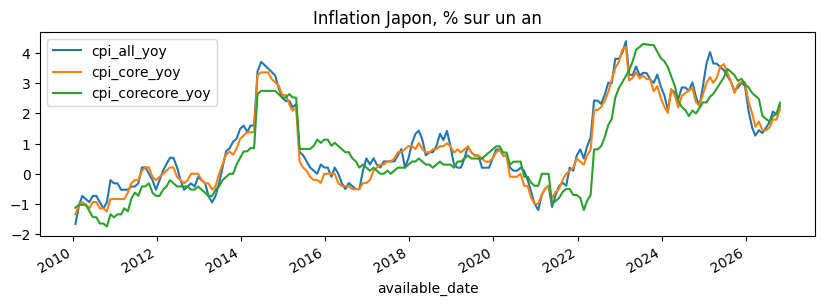

In [47]:
if cpi is not None:
    cpi.loc[START:, ["cpi_all_yoy", "cpi_core_yoy", "cpi_corecore_yoy"]].plot(figsize=(10, 3), title="Inflation Japon, % sur un an");

## Étape 9 : calendrier des réunions de la BoJ

Deux pages du site de la BoJ :
- `past.htm` : réunions de 2010 à l'an dernier
- `index.htm` : année en cours et suivante (y compris les réunions **à venir**)

Chaque année est un tableau (`<h2 id="pAAAA">`). La 1re colonne donne les dates de la réunion :
- réunion passée : un lien vers le communiqué, dont le nom encode la date de décision (`k250124a.pdf` → 24/01/2025)
- réunion future : seulement du texte, ex. `Dec. 17 (Thurs.), 18 (Fri.)` → la décision tombe le dernier jour

La 2e colonne n'est remplie que si un **Outlook Report** (prévisions trimestrielles) est publié à cette réunion.

La page en ligne commence en 2010 : on ajoute à la main la dernière réunion de 2009 (17-18 décembre 2009), sinon
« jours depuis la dernière réunion » serait vide pour janvier 2010.

In [48]:
MONTHS = {"Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "June": 6, "July": 7,
          "Aug": 8, "Sept": 9, "Oct": 10, "Nov": 11, "Dec": 12}
DAY_RE = re.compile(r"(?:(Jan|Feb|Mar|Apr|May|June|July|Aug|Sept|Oct|Nov|Dec)\.?\s+)?(\d{1,2})\s*\(")

def download_boj_calendar():
    rows = [(pd.Timestamp("2009-12-18"), False)]                   # dernière réunion de 2009
    for url in ["https://www.boj.or.jp/en/mopo/mpmsche_minu/past.htm",
                "https://www.boj.or.jp/en/mopo/mpmsche_minu/index.htm"]:
        html = get(url).text
        for section in re.split(r'<h2 id="p(?=\d{4}")', html)[1:]:
            year = int(section[:4])
            for tr in re.findall(r"<tr>(.*?)</tr>", section, flags=re.S):
                tds = re.findall(r"<td[^>]*>(.*?)</td>", tr, flags=re.S)
                if not tds:
                    continue
                m = re.search(r"mpmdeci/mpr_\d{4}/k(\d{6})", tds[0])
                if m:                                               # réunion passée
                    date = pd.to_datetime(m.group(1), format="%y%m%d")
                else:                                               # réunion à venir
                    hits = DAY_RE.findall(re.sub(r"<[^>]+>", " ", tds[0]))
                    if not hits:
                        continue
                    month = [MONTHS[mo] for mo, _ in hits if mo][-1]
                    date = pd.Timestamp(year, month, int(hits[-1][1]))
                outlook = len(tds) > 1 and re.sub(r"<[^>]+>|\s", "", tds[1]) not in ("", "-")
                rows.append((date, outlook))
    return (pd.DataFrame(rows, columns=["boj_decision_date", "outlook_report"])
            .drop_duplicates("boj_decision_date").set_index("boj_decision_date").sort_index())

boj_cal = load_source("boj_calendar", download_boj_calendar)
boj_cal.tail(8) if boj_cal is not None else None

[cache] boj_calendar : relu depuis data/raw/boj_calendar.csv (sauvegardé il y a 2.8 h)
        185 lignes, 2009-12-18 -> 2027-12-17


,outlook_report
boj_decision_date,
2027-01-22,True
2027-03-18,False
2027-04-28,True
2027-06-11,False
2027-07-22,True
2027-09-22,False
2027-10-29,True
2027-12-17,False


## Étape 10 : les news (GDELT)

[GDELT](https://www.gdeltproject.org/) analyse en continu les articles de presse en ligne du monde entier (plus de
100 langues). Son API **DOC 2.0**, gratuite et sans clé, donne pour une requête de mots-clés deux séries quotidiennes :

- `timelinetone` : **ton moyen** des articles du jour (de −10, très négatif, à +10, très positif ; en pratique entre −5 et +2) ;
- `timelinevolraw` : **nombre d'articles** du jour, et nombre total d'articles suivis par GDELT ce jour-là.

On suit deux thèmes :

| Thème | Requête |
|---|---|
| `japan` | économie et marchés japonais (Nikkei, yen, actions japonaises…) |
| `boj` | Banque du Japon |

Contraintes de l'API : pas de données avant **2017**, et **une requête toutes les 5 secondes au maximum**. Si GDELT
répond « trop de requêtes » (erreur 429, fréquente quand le serveur est chargé), la fonction attend et réessaie
toute seule, pendant `NEWS_BUDGET_S` secondes au plus. Ensuite :
- s'il existe une sauvegarde des news (`data/raw/gdelt_news.csv`), elle est utilisée : on perd seulement les
  derniers jours, l'historique ne change pas ;
- sinon le notebook continue sans news (`dataset_ml.csv` est quand même produit) : relance simplement cette cellule
  et les suivantes un peu plus tard.

Pourquoi pas le Guardian ou le New York Times ? Leurs API demandent une clé personnelle (la clé de test du Guardian ne
fonctionne plus), et celle du NYT est limitée à 5 requêtes par minute.

In [49]:
NEWS_QUERIES = {
    "japan": '("Japanese economy" OR "Japan economy" OR Nikkei OR "Japanese stocks" OR "Tokyo stocks" OR "Japanese yen")',
    "boj": '"Bank of Japan"',
}

NEWS_BUDGET_S = 60    # temps maximum accordé à GDELT ; au-delà on garde la sauvegarde des news

def gdelt(query, mode, deadline):
    params = dict(query=query, mode=mode, format="csv",
                  startdatetime=NEWS_START.replace("-", "") + "000000",
                  enddatetime=pd.Timestamp.now(tz="UTC").strftime("%Y%m%d%H%M%S"))
    wait = 10
    while time.time() < deadline:
        try:
            r = session.get("https://api.gdeltproject.org/api/v2/doc/doc", params=params, timeout=(30, 90))
            if r.status_code == 429 or "limit requests" in r.text[:300]:
                print(f"    GDELT demande de ralentir (trop de requêtes), nouvel essai dans {wait} s")
            else:
                r.raise_for_status()
                df = pd.read_csv(io.StringIO(r.text.lstrip("\ufeff")))
                if "Date" not in df.columns:
                    raise RuntimeError(f"GDELT : {r.text[:150]}")
                time.sleep(6)                         # limite : 1 requête toutes les 5 s
                return df.pivot_table(index="Date", columns="Series", values="Value")
        except requests.RequestException as e:
            print(f"    GDELT ne répond pas ({type(e).__name__}), nouvel essai dans {wait} s")
        time.sleep(wait)
        wait = min(wait * 2, 40)
    raise TimeoutError(f"GDELT indisponible pendant {NEWS_BUDGET_S} s : relance cette cellule plus tard")

def download_news():
    deadline = time.time() + NEWS_BUDGET_S
    out = {}
    for theme, query in NEWS_QUERIES.items():
        print(f"  GDELT : {theme}...")
        tone = gdelt(query, "timelinetone", deadline)
        vol = gdelt(query, "timelinevolraw", deadline)
        out[f"news_{theme}_tone"] = tone["Average Tone"]
        out[f"news_{theme}_count"] = vol["Article Count"]
        out["news_total_monitored"] = vol["Total Monitored Articles"]
    df = pd.DataFrame(out)
    df.index = pd.to_datetime(df.index)
    df.index.name = "date_utc"
    return df

news_raw = load_source("gdelt_news", download_news)
news_raw.tail(3) if news_raw is not None else None

[cache] gdelt_news : relu depuis data/raw/gdelt_news.csv (sauvegardé il y a 2.8 h)
        3553 lignes, 2017-01-01 -> 2026-11-09


,news_japan_tone,news_japan_count,news_total_monitored,news_boj_tone,news_boj_count
date_utc,,,,,
2026-11-07,-1.6525,25.0,29862.0,-0.7436,3.0
2026-11-08,-0.5873,9.0,28220.0,-2.7821,1.0
2026-11-09,-0.2777,34.0,12731.0,-0.7104,6.0


### Rattacher les news aux séances de Tokyo, sans fuite

Les dates GDELT sont des **jours UTC**. Le jour UTC d se termine à minuit UTC, soit **9h00 à Tokyo le jour d+1** :
toutes ses news sont donc connues à l'ouverture de Tokyo du lendemain. On rattache le jour UTC d à la **première séance
de Tokyo à partir de d+1**. Les news du week-end et des jours fériés s'additionnent sur la séance suivante.

Variables créées, pour chaque thème :

| Colonne | Définition |
|---|---|
| `news_<thème>_tone` | ton moyen des articles, pondéré par leur nombre |
| `news_<thème>_tone_5d` | moyenne du ton sur les 5 dernières séances (moins bruité) |
| `news_<thème>_share` | articles du thème pour 10 000 articles suivis par GDELT (corrige la croissance de GDELT dans le temps) |
| `news_<thème>_attention` | écart de `share` à sa moyenne des 60 dernières séances, en écarts-types (pic d'actualité) |

In [50]:
news = None
if news_raw is not None:
    days = n225.index
    pos = np.searchsorted(days.values, (news_raw.index + pd.Timedelta(days=1)).values, side="left")
    ok = pos < len(days)                       # les news d'aujourd'hui serviront à la prochaine séance
    nr = news_raw[ok].copy()
    nr["session"] = days[pos[ok]]

    news = pd.DataFrame(index=pd.DatetimeIndex(sorted(nr["session"].unique())))
    total = nr.groupby("session")["news_total_monitored"].sum()
    for theme in NEWS_QUERIES:
        cnt, tone = nr[f"news_{theme}_count"], nr[f"news_{theme}_tone"]
        g = pd.DataFrame({"w": cnt * tone, "n": cnt, "session": nr["session"]}).groupby("session").sum()
        news[f"news_{theme}_tone"] = (g["w"] / g["n"].replace(0, np.nan)).ffill()
        news[f"news_{theme}_tone_5d"] = news[f"news_{theme}_tone"].rolling(5).mean()
        share = g["n"] / total * 1e4
        news[f"news_{theme}_share"] = share
        news[f"news_{theme}_attention"] = (share - share.rolling(60).mean()) / share.rolling(60).std()
    news.index.name = "date"
    print(f"{len(news)} séances avec news, {news.index.min().date()} -> {news.index.max().date()}")
news.tail(3) if news is not None else None

2378 séances avec news, 2017-01-04 -> 2026-11-09


,news_japan_tone,news_japan_tone_5d,news_japan_share,news_japan_attention,news_boj_tone,news_boj_tone_5d,news_boj_share,news_boj_attention
date,,,,,,,,
2026-11-05,-0.474600,-1.282672,9.009009,-1.296865,-1.56640,-1.312695,0.000000,-1.148203
2026-11-06,-1.385100,-1.189060,26.741543,1.471728,-1.56640,-1.280180,0.000000,-1.137496
2026-11-09,-2.840133,-1.437747,38.741643,3.042119,-0.49685,-1.352490,1.229893,-0.787000


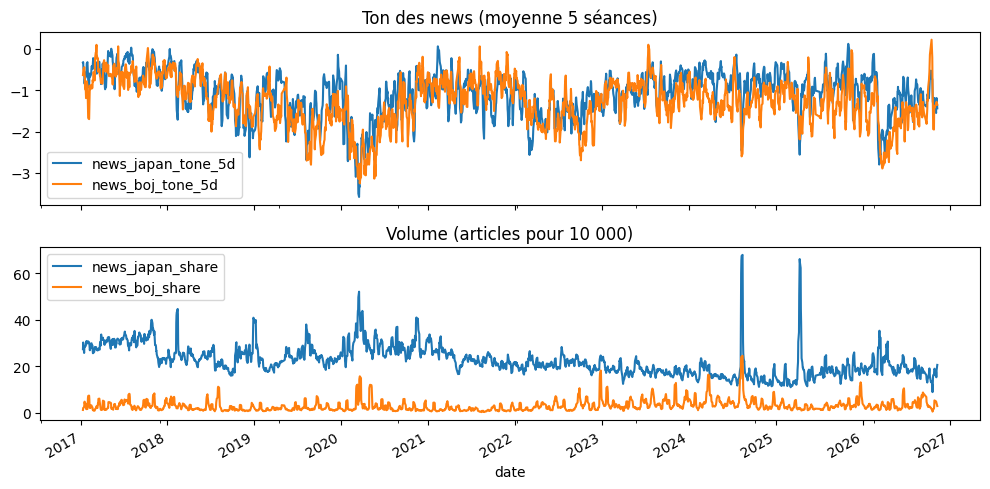

In [51]:
if news is not None:
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    news[["news_japan_tone_5d", "news_boj_tone_5d"]].plot(ax=ax[0], title="Ton des news (moyenne 5 séances)")
    news[["news_japan_share", "news_boj_share"]].rolling(5).mean().plot(ax=ax[1], title="Volume (articles pour 10 000)")
    plt.tight_layout();

## Étape 11 : données manuelles (optionnel)

Certaines séries n'ont pas de téléchargement libre et automatisable :

| Série | Où la trouver |
|---|---|
| Nikkei VI | Investing.com, site Nikkei Indexes |
| TOPIX officiel, TOPIX Value / Growth, Core30, Growth 250 | JPX, Investing.com |
| MSCI EM officiel | site MSCI (outil de recherche des niveaux d'indices en fin de journée) |
| PMI manufacturier Japon | S&P Global, calendrier économique d'Investing.com |

Dépose le CSV dans `data/1_brutes/saisie_manuelle/`, puis relance cette cellule. **Le nom du fichier devient le nom de la colonne**
(ex. `nikkei_vi.csv` → `nikkei_vi`). Formats acceptés : export Investing.com (`Date`, `Price`, …) ou deux colonnes
`date,valeur`.

⚠️ Pour le PMI (mensuel), la date doit être la date de **publication** (1er jour ouvré du mois suivant), pas le mois
de référence, sinon le modèle verra le chiffre avant sa sortie.

In [52]:
manual = {}
for f in sorted(MANUAL.glob("*.csv")):
    df = pd.read_csv(f, thousands=",")
    val_col = "Price" if "Price" in df.columns else df.columns[1]
    s = pd.to_numeric(df[val_col].astype(str).str.replace(",", ""), errors="coerce")
    s.index = pd.to_datetime(df[df.columns[0]], errors="coerce")
    s = s[s.index.notna()].dropna().sort_index()
    manual[f.stem] = s[~s.index.duplicated(keep="last")]
    print(f"{f.name} : {len(s)} lignes, {s.index.min().date()} -> {s.index.max().date()}")

manual_df = pd.DataFrame(manual) if manual else None
if manual_df is None:
    print("Aucun fichier dans data/1_brutes/saisie_manuelle/ (ce n'est pas bloquant).")

Aucun fichier dans data/manual/ (ce n'est pas bloquant).


## Étape 12 : fusion sur le calendrier de Tokyo

L'index est celui du Nikkei (jours de bourse de Tokyo, depuis `FETCH_START`). Pour chaque source, on prend **la
dernière valeur connue** à chaque date (*as-of join*) :

1. on ajoute les dates de Tokyo à l'index de la source ;
2. on propage les valeurs vers l'avant (`ffill`), jamais vers l'arrière ;
3. on ne garde que les dates de Tokyo.

Les séries mensuelles et trimestrielles (CPI, Tankan, Euribor) ont déjà été datées à leur date de disponibilité :
elles restent donc constantes jusqu'à la publication suivante.

Le volume du Nikkei vaut parfois 0 sur Yahoo (donnée absente, pas un vrai volume nul) : on le remplace par la
dernière valeur connue.

In [53]:
def asof_join(base, other):
    other = other[~other.index.duplicated(keep="last")].sort_index()
    aligned = other.reindex(other.index.union(base.index)).ffill().reindex(base.index)
    return base.join(aligned)

ds = n225.copy()
ds["n225_volume"] = ds["n225_volume"].replace(0, np.nan).ffill()
for part in [yahoo, fred_df, jgb, bund, ecb_df, tona, tankan, cpi, manual_df]:
    if part is not None:
        ds = asof_join(ds, part)
if news is not None:
    ds = ds.join(news)       # déjà rattachées aux séances de Tokyo : pas de ffill

EXPECTED = ["sp500", "taiex", "shanghai", "nifty50", "msci_em_eem", "topix_etf", "topix_core30_etf",
            "growth250_etf", "usdjpy_yahoo", "eurjpy", "us10y", "vix", "jgb2y", "jgb5y", "jgb10y", "jgb30y",
            "bund10y", "euribor3m_mavg", "eur_overnight", "tona", "tankan_large_manuf",
            "tankan_large_nonmanuf", "tankan_large_manuf_fcst", "cpi_all", "cpi_core", "cpi_corecore",
            "cpi_all_yoy", "cpi_core_yoy", "cpi_corecore_yoy"]
for col in EXPECTED:
    if col not in ds:
        print(f"colonne absente (source ignorée) : {col}")
        ds[col] = np.nan

# USD/JPY : Yahoo en priorité, FRED en secours ; les colonnes de secours sont ensuite retirées
ds["usdjpy"] = ds["usdjpy_yahoo"]
if "usdjpy_fred" in ds:
    ds["usdjpy"] = ds["usdjpy"].combine_first(ds["usdjpy_fred"])
ds = ds.drop(columns=["usdjpy_yahoo", "usdjpy_fred", "us10y_yahoo", "vix_yahoo"], errors="ignore")
ds.shape

(4361, 42)

## Étape 13 : variables calculées

### Indicateurs techniques sur le Nikkei
Calculés avec pandas (pas besoin de la librairie `ta`), sur tout l'historique depuis `FETCH_START` : grâce à l'année
d'amorçage, ils sont tous définis dès le 1er jour du dataset. Tous sont **normalisés** (en % ou en ratio) pour rester
comparables quand le niveau de l'indice change :

| Colonne | Définition |
|---|---|
| `n225_ret_{1,5,20,60}d` | rendement sur n jours |
| `n225_dist_sma{20,50,200}` | écart à la moyenne mobile : close / SMA − 1 |
| `n225_vol_20d` | volatilité réalisée 20 j, annualisée |
| `n225_rsi14` | RSI de Wilder, 14 j |
| `n225_macd`, `n225_macd_hist` | MACD (12, 26, 9) divisé par le prix |
| `n225_bb_pctb` | position dans les bandes de Bollinger (20 j, 2σ) : 0 = bande basse, 1 = bande haute |
| `n225_atr14_pct` | Average True Range 14 j, divisé par le prix |

In [54]:
c, h, l = ds["n225_close"], ds["n225_high"], ds["n225_low"]
logret = np.log(c).diff()

ds["n225_ret_1d"] = c.pct_change()
for n in (5, 20, 60):
    ds[f"n225_ret_{n}d"] = c.pct_change(n)
for n in (20, 50, 200):
    ds[f"n225_dist_sma{n}"] = c / c.rolling(n).mean() - 1
ds["n225_vol_20d"] = logret.rolling(20).std() * np.sqrt(252)

# RSI (lissage de Wilder = EWM avec alpha = 1/14)
delta = c.diff()
gain = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()
loss = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean()
ds["n225_rsi14"] = 100 - 100 / (1 + gain / loss)

# MACD
macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
ds["n225_macd"] = macd / c
ds["n225_macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c

# Bollinger %b
mid, sd = c.rolling(20).mean(), c.rolling(20).std()
ds["n225_bb_pctb"] = (c - (mid - 2 * sd)) / (4 * sd)

# ATR
tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
ds["n225_atr14_pct"] = tr.ewm(alpha=1/14, adjust=False).mean() / c

ds.loc[START:].filter(like="n225_").head(3)

,n225_open,n225_high,n225_low,n225_close,n225_volume,n225_ret_1d,n225_ret_5d,n225_ret_20d,n225_ret_60d,n225_dist_sma20,n225_dist_sma50,n225_dist_sma200,n225_vol_20d,n225_rsi14,n225_macd,n225_macd_hist,n225_bb_pctb,n225_atr14_pct
Date,,,,,,,,,,,,,,,,,,
2010-01-04,10609.339844,10694.490234,10608.139648,10654.790039,104400000.0,0.010274,0.011186,0.108841,0.094835,0.039376,0.067231,0.103939,0.205329,68.255048,0.019582,0.004546,0.908265,0.013849
2010-01-05,10719.440430,10791.040039,10655.570312,10681.830078,166200000.0,0.002538,0.017830,0.070574,0.104123,0.038447,0.069201,0.104682,0.165631,68.922885,0.020093,0.004076,0.885975,0.013738
2010-01-06,10709.549805,10768.610352,10661.169922,10731.450195,181800000.0,0.004645,0.009142,0.070726,0.107271,0.039689,0.073312,0.107708,0.165644,70.163340,0.020578,0.003708,0.884193,0.013413


### Variables BoJ
- `boj_meeting_day` : 1 le jour d'une décision de politique monétaire
- `boj_outlook_day` : 1 si un Outlook Report est publié ce jour-là
- `boj_days_to_next` / `boj_days_since_last` : jours calendaires avant la prochaine réunion et depuis la dernière

Les dates des réunions sont annoncées environ un an à l'avance, donc `boj_days_to_next` n'est pas une fuite d'information.

In [55]:
if boj_cal is not None:
    dates = boj_cal.index.values
    idx = ds.index.values
    nxt_pos = np.searchsorted(dates, idx, side="left")          # 1re réunion >= date
    prv_pos = np.searchsorted(dates, idx, side="right") - 1     # dernière réunion <= date
    nxt = pd.to_datetime(np.where(nxt_pos < len(dates), dates[np.minimum(nxt_pos, len(dates) - 1)], np.datetime64("NaT")))
    prv = pd.to_datetime(np.where(prv_pos >= 0, dates[np.maximum(prv_pos, 0)], np.datetime64("NaT")))

    ds["boj_meeting_day"] = ds.index.isin(boj_cal.index).astype(int)
    ds["boj_outlook_day"] = ds.index.isin(boj_cal.index[boj_cal["outlook_report"].astype(bool)]).astype(int)
    ds["boj_days_to_next"] = (nxt - ds.index).days
    ds["boj_days_since_last"] = (ds.index - prv).days
else:
    print("Calendrier BoJ indisponible : variables BoJ non créées")

ds.loc["2024-03-14":"2024-03-22", ["n225_close", "tona", "boj_meeting_day", "boj_days_to_next", "boj_days_since_last"]]

,n225_close,tona,boj_meeting_day,boj_days_to_next,boj_days_since_last
Date,,,,,
2024-03-14,38807.378906,-0.009,0,5,51.0
2024-03-15,38707.640625,-0.005,0,4,52.0
2024-03-18,39740.441406,-0.003,0,1,55.0
2024-03-19,40003.601562,-0.001,1,0,0.0
2024-03-21,40815.660156,0.074,0,36,2.0
2024-03-22,40888.429688,0.077,0,35,3.0


Exemple ci-dessus : le 19 mars 2024, la BoJ sort des taux négatifs, et on voit le TONA passer de −0,001 % à +0,074 %.

### Écarts de taux

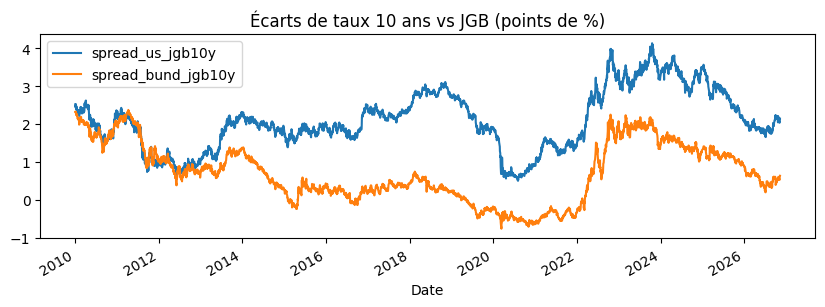

In [56]:
ds["spread_us_jgb10y"] = ds["us10y"] - ds["jgb10y"]
ds["spread_bund_jgb10y"] = ds["bund10y"] - ds["jgb10y"]
ds.loc[START:, ["spread_us_jgb10y", "spread_bund_jgb10y"]].plot(figsize=(10, 3), title="Écarts de taux 10 ans vs JGB (points de %)");

## Étape 14 : décalage horaire et dataset prêt pour le ML

Tokyo ferme à **15h30 heure de Tokyo (6h30 UTC)**, avant l'Europe et les États-Unis. Pour prédire le Nikkei à partir
de la clôture du jour t, chaque variable doit être décalée du nombre de jours nécessaire pour être **connue avant la
clôture de Tokyo** :

| Décalage | Variables | Raison |
|---|---|---|
| 0 | Nikkei et indicateurs, TAIEX, ETF japonais, CPI, Tankan, BoJ, news | connues avant 15h30 à Tokyo (macro et news déjà datées à leur publication) |
| 1 jour | S&P 500, VIX, US 10 ans, Bund, MSCI EM, Nifty, **Shanghai** (ferme à 7h00 UTC), USD/JPY, EUR/JPY, JGB, TONA, Euribor, écarts de taux | clôture ou publication après celle de Tokyo |
| 2 jours | `eur_overnight` | l'€STR du jour d est publié le matin de d+1 à 8h00 heure de Francfort, après la clôture de Tokyo |

On ajoute la cible d'exemple : `target_ret_next_1d`, rendement du Nikkei de la clôture t à la clôture t+1.

In [57]:
LAGS = {
    1: ["sp500", "vix", "us10y", "bund10y", "msci_em_eem", "nifty50", "shanghai", "usdjpy", "eurjpy",
        "jgb2y", "jgb5y", "jgb10y", "jgb30y", "tona", "euribor3m_mavg", "spread_us_jgb10y", "spread_bund_jgb10y"],
    2: ["eur_overnight"],
}
ds_ml = ds.copy()
for lag, cols in LAGS.items():
    ds_ml[cols] = ds_ml[cols].shift(lag)       # décalage sur tout l'historique (depuis 2009) : pas de trou en 2010

ds_ml["target_ret_next_1d"] = ds_ml["n225_close"].shift(-1) / ds_ml["n225_close"] - 1

# On ne garde que la période du dataset
ds = ds.loc[START:]
ds_ml = ds_ml.loc[START:]
ds_ml[["n225_close", "sp500", "usdjpy", "target_ret_next_1d"]].tail(3)

,n225_close,sp500,usdjpy,target_ret_next_1d
Date,,,,
2026-11-05,61077.898438,7688.620117,158.468994,-0.059647
2026-11-06,57434.769531,7353.729980,158.356995,0.023344
2026-11-09,58775.500000,7376.859863,157.498001,NaN


### Deux fichiers ML sans aucune case vide

- `growth250_etf` est retirée : l'ETF n'est coté que depuis 2018 (ajoute l'indice officiel via `data/1_brutes/saisie_manuelle/` si besoin).
- **`dataset_ml.csv`** : toutes les variables sauf les news, sur toute la période depuis 2010.
- **`dataset_ml_news.csv`** : toutes les variables **avec les news**, à partir du moment où elles sont complètes
  (2017 + 60 séances pour `attention`).
- Dans les deux, on enlève la dernière ligne : sa cible (le rendement de demain) n'est pas encore connue.

In [58]:
NEWS_COLS = [c for c in ds_ml.columns if c.startswith("news_")]
DROP_ML = ["growth250_etf"]

ml = ds_ml.drop(columns=DROP_ML + NEWS_COLS)
ml_news = ds_ml.drop(columns=DROP_ML)
if NEWS_COLS:
    ml_news = ml_news.loc[ml_news[NEWS_COLS].notna().all(axis=1).idxmax():]   # 1er jour où toutes les news existent

for name, df in [("dataset_ml", ml), ("dataset_ml_news", ml_news)]:
    before = len(df)
    na = df.isna().sum()
    print(f"{name} : {before} lignes ; cases vides avant nettoyage : {na.sum()} "
          f"({', '.join(f'{c}={n}' for c, n in na[na > 0].items()) or 'aucune'})")

ml, ml_news = ml.dropna(), ml_news.dropna()
assert ml.isna().sum().sum() == 0 and ml_news.isna().sum().sum() == 0
print(f"\ndataset_ml      : {ml.shape[0]} lignes x {ml.shape[1]} colonnes, {ml.index.min().date()} -> {ml.index.max().date()}, 0 case vide")
print(f"dataset_ml_news : {ml_news.shape[0]} lignes x {ml_news.shape[1]} colonnes, {ml_news.index.min().date()} -> {ml_news.index.max().date()}, 0 case vide")

dataset_ml : 4119 lignes ; cases vides avant nettoyage : 1 (target_ret_next_1d=1)
dataset_ml_news : 2346 lignes ; cases vides avant nettoyage : 217 (news_japan_tone=27, news_japan_tone_5d=27, news_japan_share=27, news_japan_attention=27, news_boj_tone=27, news_boj_tone_5d=27, news_boj_share=27, news_boj_attention=27, target_ret_next_1d=1)

dataset_ml      : 4118 lignes x 53 colonnes, 2010-01-04 -> 2026-11-06, 0 case vide
dataset_ml_news : 2318 lignes x 61 colonnes, 2017-03-30 -> 2026-11-06, 0 case vide


## Étape 15 : contrôles qualité

- **Cases vides du fichier complet** (`dataset_daily.csv`) : elles ne doivent venir que de séries qui n'existaient pas
  encore (Growth 250 avant 2018, news avant 2017) et de la cible de la dernière ligne.
- **Fraîcheur** : la dernière date réelle de chaque source, pour repérer une source qui a cessé de se mettre à jour
  (un `ffill` masquerait le problème).

In [59]:
na = ds.isna().sum()
pd.DataFrame({"cases vides": na, "%": (na / len(ds) * 100).round(1),
              "1re valeur": ds.apply(lambda s: s.first_valid_index()).dt.date})[na > 0]

,cases vides,%,1re valeur
growth250_etf,1978,48.0,2018-01-30
news_japan_tone,1741,42.3,2017-01-04
news_japan_tone_5d,1745,42.4,2017-01-11
news_japan_share,1741,42.3,2017-01-04
news_japan_attention,1800,43.7,2017-03-30
news_boj_tone,1741,42.3,2017-01-04
news_boj_tone_5d,1745,42.4,2017-01-11
news_boj_share,1741,42.3,2017-01-04
news_boj_attention,1800,43.7,2017-03-30


In [60]:
sources = {"Nikkei": n225, "Yahoo": yahoo, "FRED": fred_df, "JGB": jgb, "Bund": bund, "BCE": ecb_df,
           "TONA": tona, "Tankan": tankan, "CPI": cpi, "News GDELT": news_raw}
pd.DataFrame({name: {"première": df.dropna(how="all").index.min().date(),
                     "dernière": df.dropna(how="all").index.max().date()} if df is not None else
                    {"première": "indisponible", "dernière": "indisponible"}
              for name, df in sources.items()}).T

,première,dernière
Nikkei,2009-01-05,2026-11-09
Yahoo,2009-01-01,2026-11-09
FRED,2009-01-02,2026-11-05
JGB,2009-01-05,2026-11-06
Bund,2009-01-02,2026-11-09
BCE,2009-01-02,2026-11-06
TONA,2009-01-05,2026-11-05
Tankan,2009-01-05,2026-10-05
CPI,2009-01-25,2026-10-25
News GDELT,2017-01-01,2026-11-09


## Étape 16 : sauvegarde

In [61]:
for df in (ds, ml, ml_news):
    df.index.name = "date"
files = ["dataset_ml.csv", "dataset_daily.csv"]
ml.to_csv(DATA / "dataset_ml.csv", float_format="%.6g")
ds.to_csv(DATA / "dataset_daily.csv", float_format="%.6g")
if NEWS_COLS:
    ml_news.to_csv(DATA / "dataset_ml_news.csv", float_format="%.6g")
    files.insert(1, "dataset_ml_news.csv")
else:
    print("⚠️ News indisponibles : dataset_ml_news.csv non mis à jour. Relance l'étape 10 et les suivantes plus tard.\n")

for f in files:
    d = pd.read_csv(DATA / f, index_col=0)
    print(f"{f:<22} {d.shape[0]:>5} lignes x {d.shape[1]:>2} colonnes   cases vides : {d.isna().sum().sum()}")
print("\nColonnes de dataset_ml_news :", ", ".join(ml_news.columns))

dataset_ml.csv          4118 lignes x 53 colonnes   cases vides : 0
dataset_ml_news.csv     2318 lignes x 61 colonnes   cases vides : 0
dataset_daily.csv       4119 lignes x 61 colonnes   cases vides : 16032

Colonnes de dataset_ml_news : n225_open, n225_high, n225_low, n225_close, n225_volume, sp500, taiex, shanghai, nifty50, msci_em_eem, topix_etf, topix_core30_etf, eurjpy, us10y, vix, jgb2y, jgb5y, jgb10y, jgb30y, bund10y, eur_overnight, euribor3m_mavg, tona, tankan_large_manuf, tankan_large_nonmanuf, tankan_large_manuf_fcst, cpi_all, cpi_core, cpi_corecore, cpi_all_yoy, cpi_core_yoy, cpi_corecore_yoy, news_japan_tone, news_japan_tone_5d, news_japan_share, news_japan_attention, news_boj_tone, news_boj_tone_5d, news_boj_share, news_boj_attention, usdjpy, n225_ret_1d, n225_ret_5d, n225_ret_20d, n225_ret_60d, n225_dist_sma20, n225_dist_sma50, n225_dist_sma200, n225_vol_20d, n225_rsi14, n225_macd, n225_macd_hist, n225_bb_pctb, n225_atr14_pct, boj_meeting_day, boj_outlook_day, boj_days_t

In [62]:
# Pour charger le dataset dans un autre notebook :
# df = pd.read_csv("../data/2_construites/dataset_ml_news.csv", index_col="date", parse_dates=True)